# View the recorded LEG-SEIR results

This notebook reads checked saved experiments and displays their results. It does not train a new model. Run it from the repository folder after downloading and verifying the experiment files using the README commands.

The average of scores from different training seeds is not the same as the error of an averaged forecast. The 2026 sample was seen earlier in the research, so it is a retrospective comparison. See `docs/GLOSSARY.md` for these terms.


In [1]:
from pathlib import Path
import json,subprocess,sys
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if not (ROOT/'scripts').exists(): ROOT=ROOT.parent
assert (ROOT/'artifacts/verified/independent_verification.json').exists(), 'Follow README fetch and verification commands first'
print(json.dumps(json.loads((ROOT/'artifacts/verified/independent_verification.json').read_text()),indent=2))
display(pd.read_csv(ROOT/'results/TEST_RESULTS.csv'))


{
  "verified": true,
  "smoke": false,
  "fits": 265,
  "code_hash": "3ea0794104f30993d7b0994c17e76e95435def0ad11305cfa535c91828009ed1",
  "hashes_checked": 915,
  "cpu_parity": true,
  "chronology_and_selection": true
}


,name,mean_RMSE,seed_SD,h1,h2,h3,parameters,reduction_vs_persistence_pct
0,lagged_full,79.634330,0.636198,41.829150,80.516563,103.874385,9519.0,8.866836
1,shared_adapter,80.756884,0.383053,40.256411,82.079912,105.844081,10476.0,7.582190
2,lagged_seir_off,81.263732,0.569785,41.045569,82.100729,106.698362,9518.0,7.002155
3,horizon_seir_off,81.362749,0.607761,42.365298,81.513327,106.821782,9443.0,6.888840
4,identity_mlp,81.392283,0.717613,39.938097,82.222392,107.312601,5095.0,6.855042
5,horizon_full,81.748689,1.282886,40.639083,82.722492,107.455430,9443.0,6.447173
6,observer_full,81.760844,1.588469,40.188326,84.453945,106.303510,9703.0,6.433263
7,observer_seir_off,82.116504,1.316723,40.947769,83.349953,107.711005,9443.0,6.026247
8,plain_graph,82.633195,1.019258,42.865866,83.218854,108.161343,9236.0,5.434948
9,uniform_mixture,83.145236,4.171663,41.185090,85.039496,108.639171,9431.0,4.848971


architecture.png


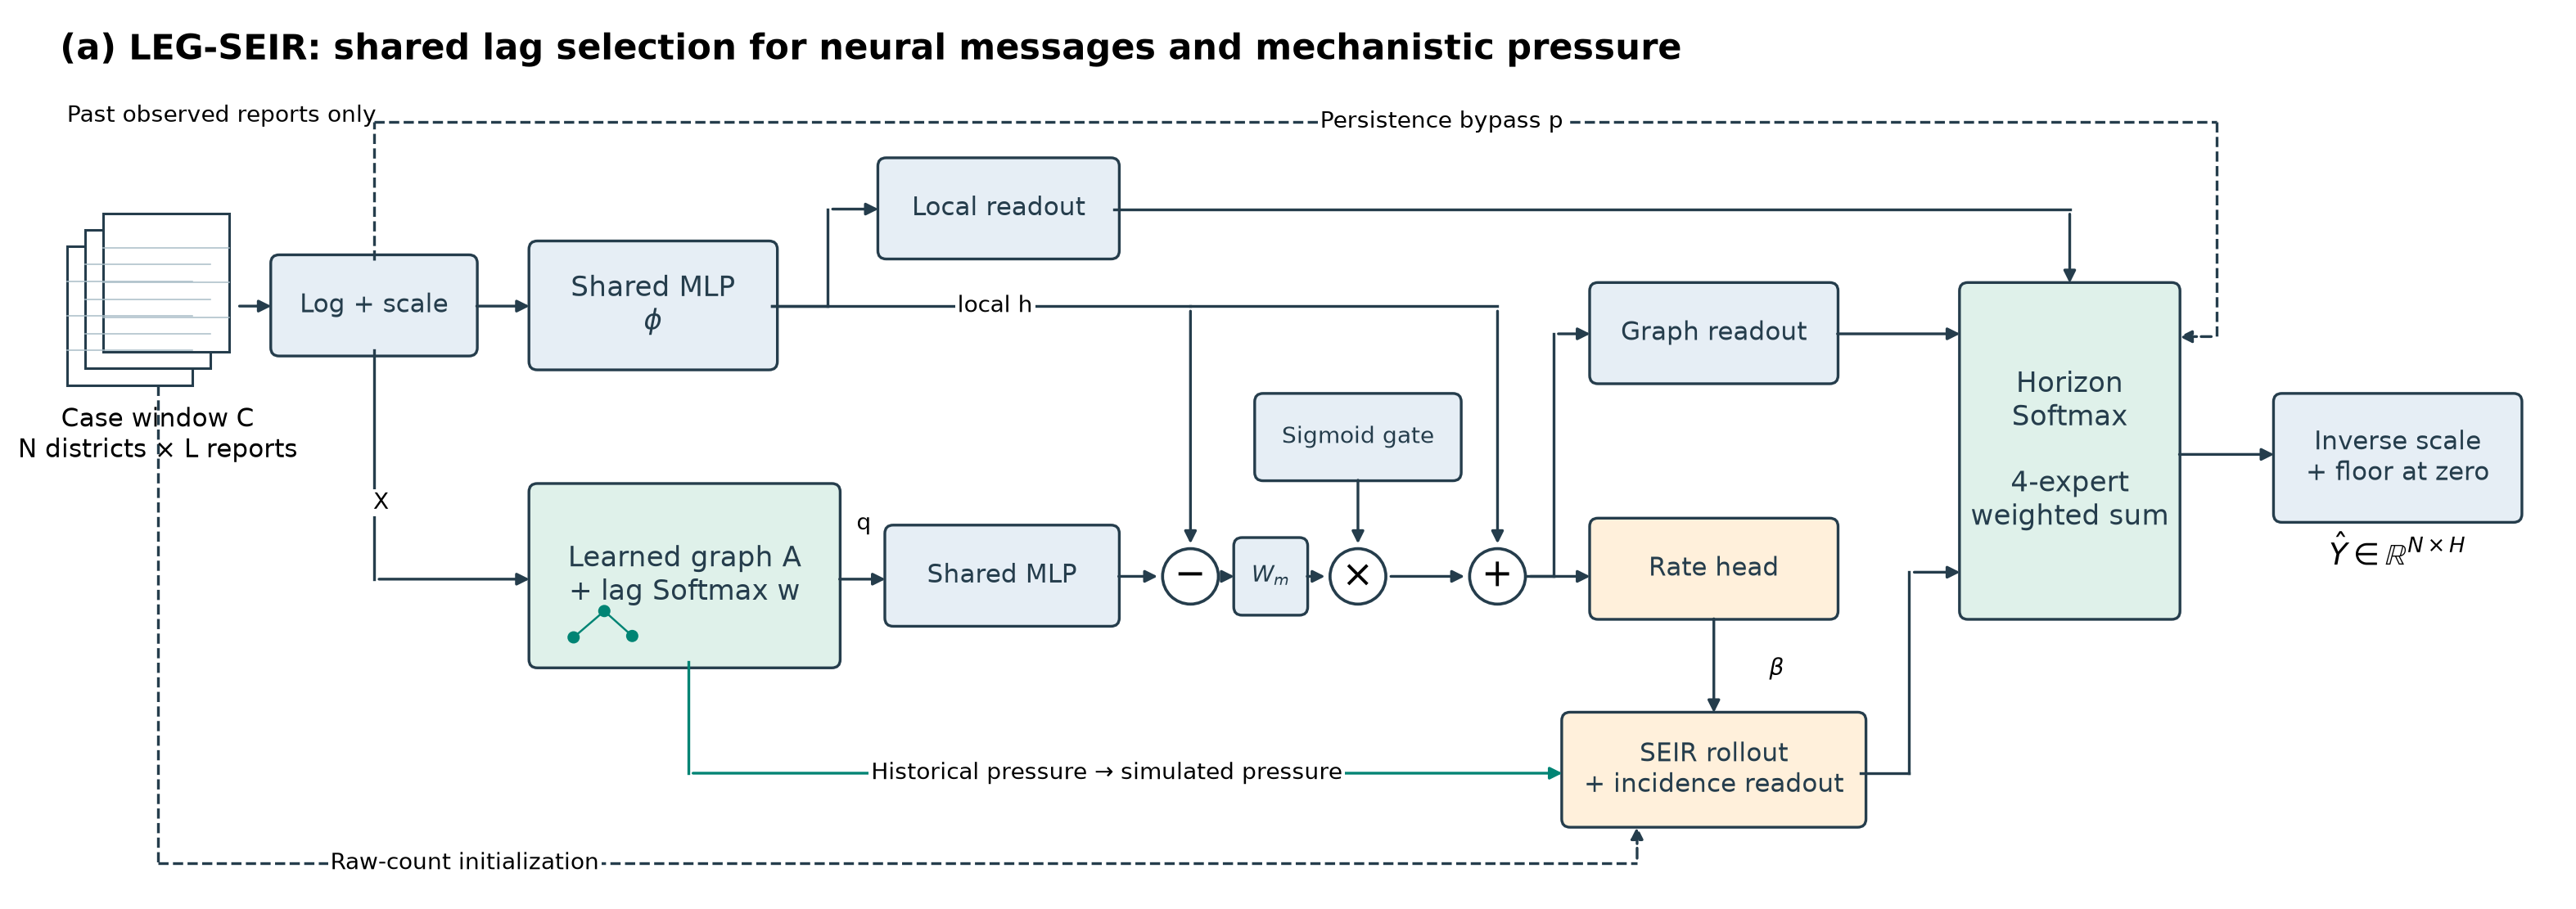

case_study.png


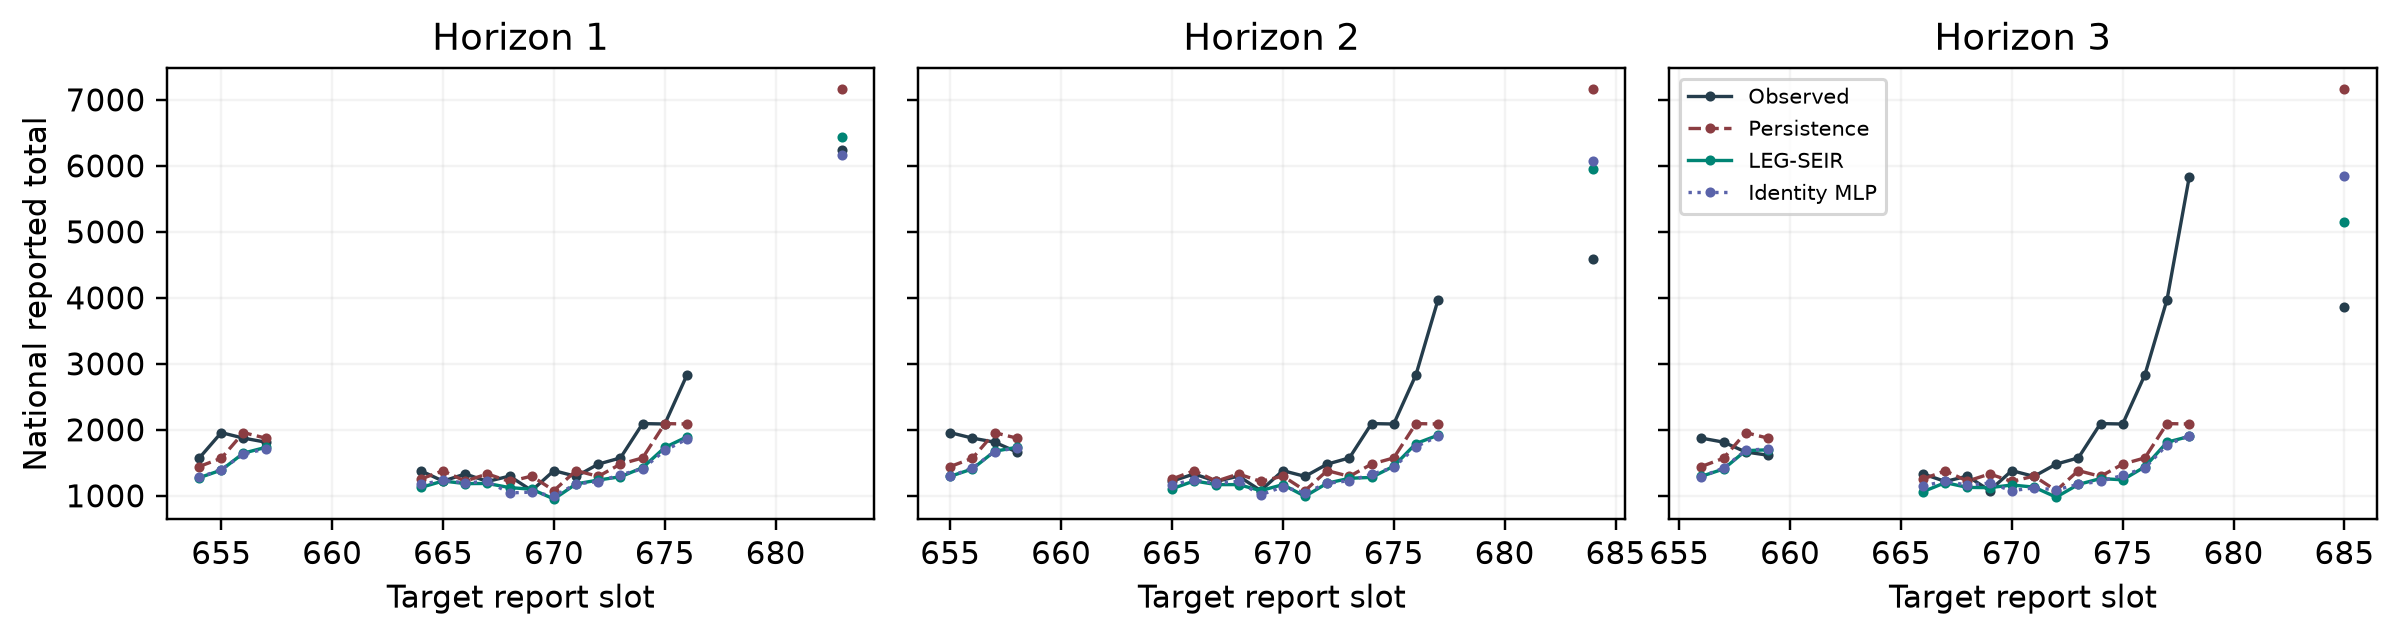

development_horizons.png


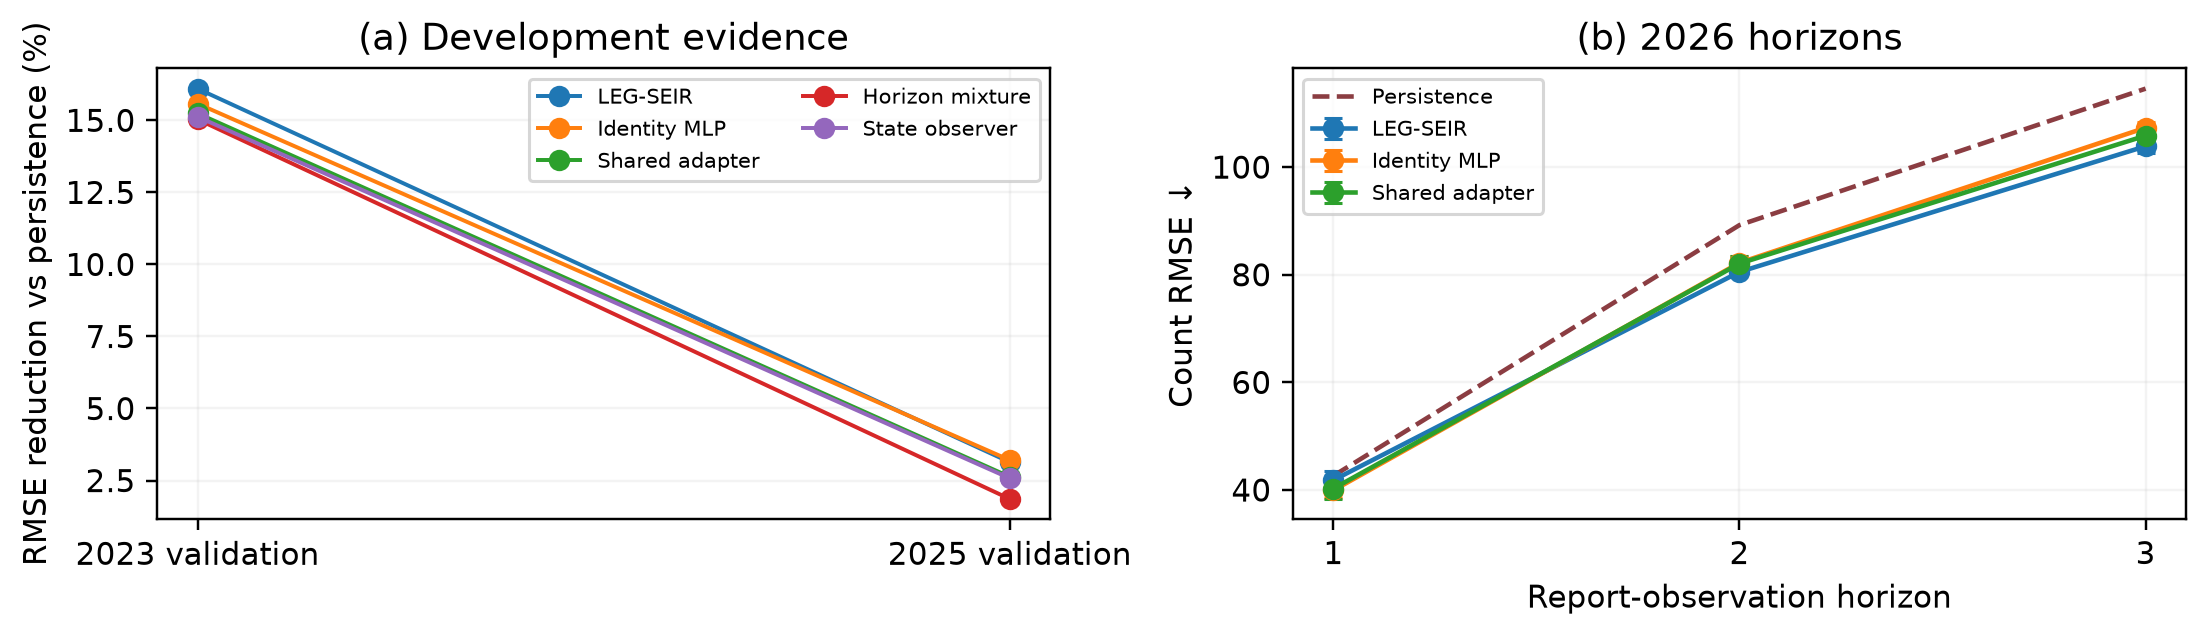

evaluation_timeline.png


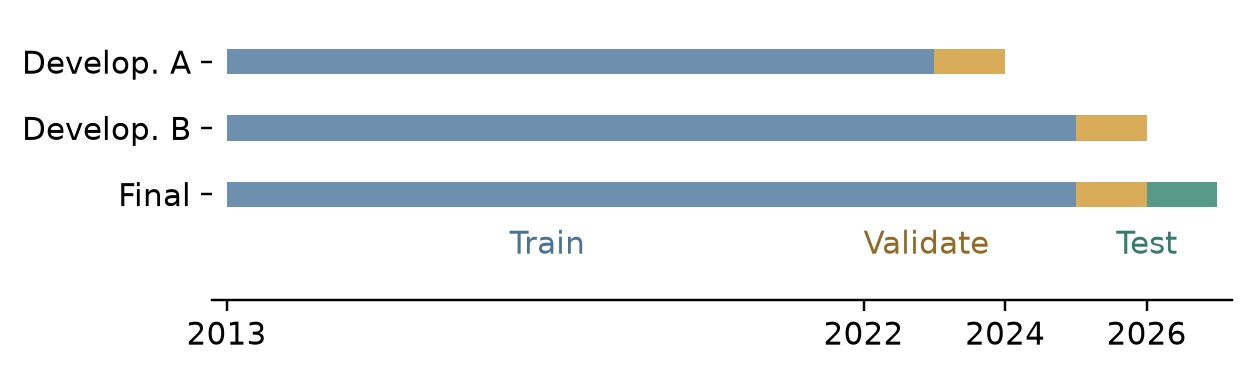

learned_diagnostics.png


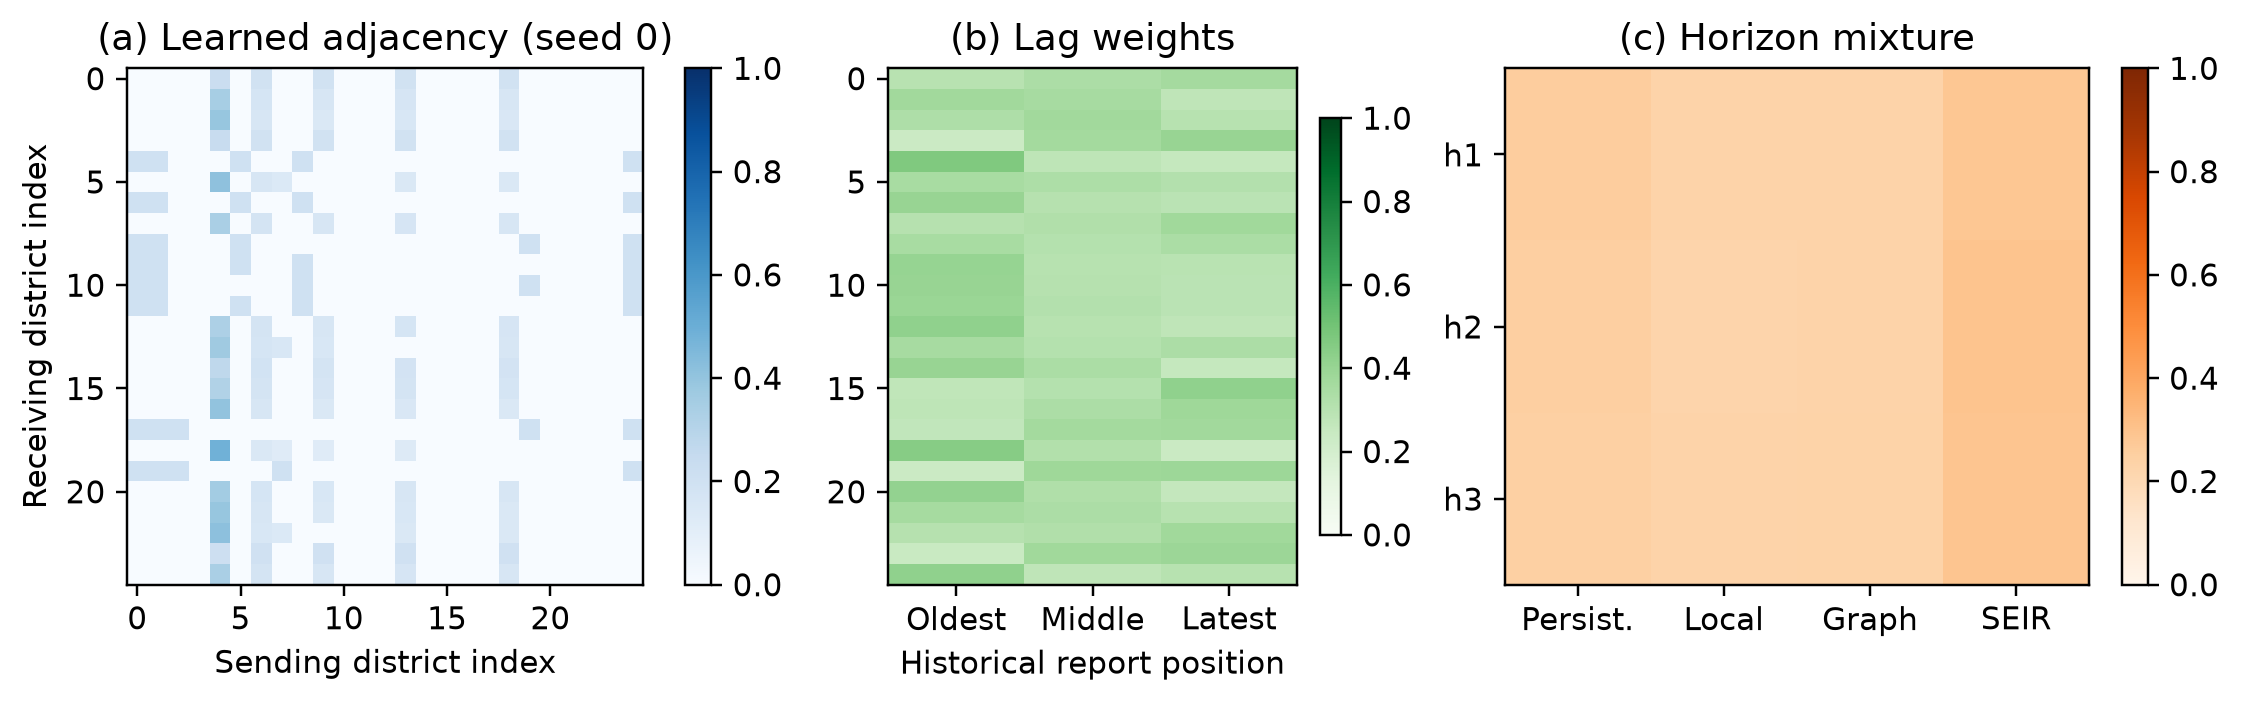

pressure_bridge.png


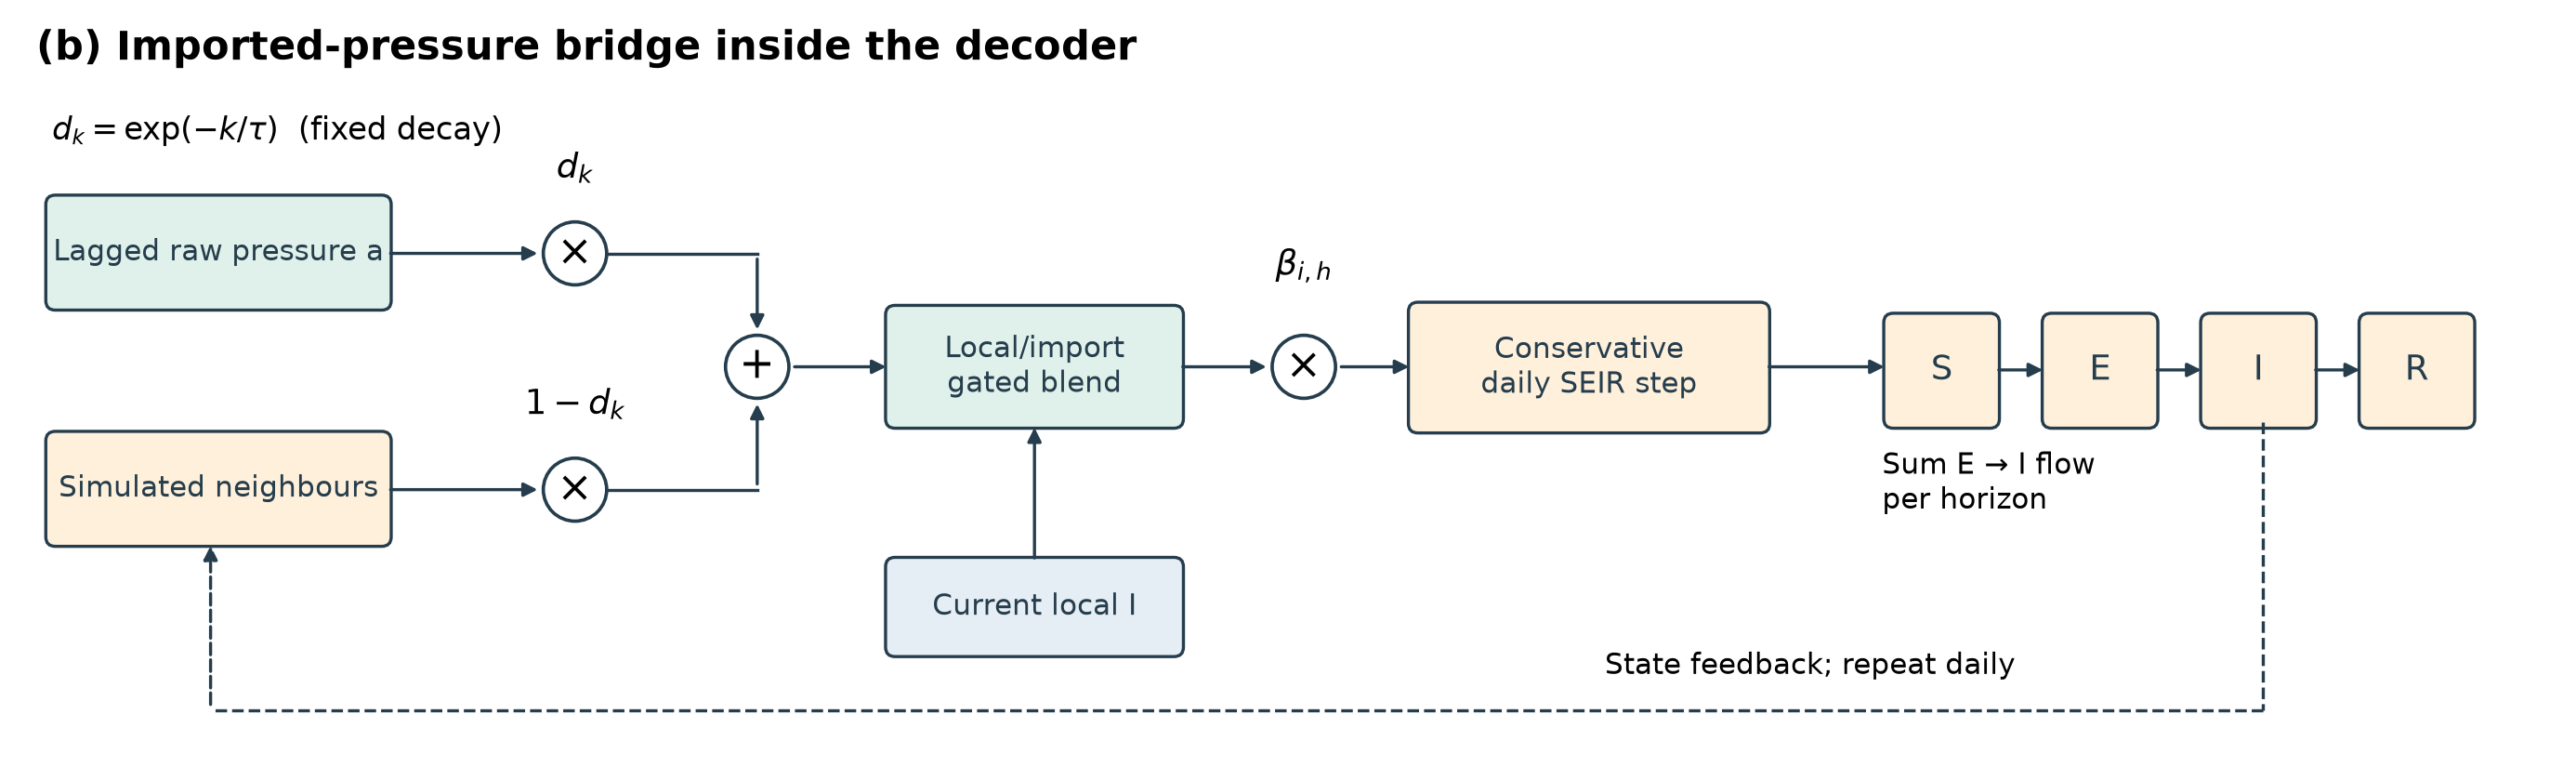

results_comparison.png


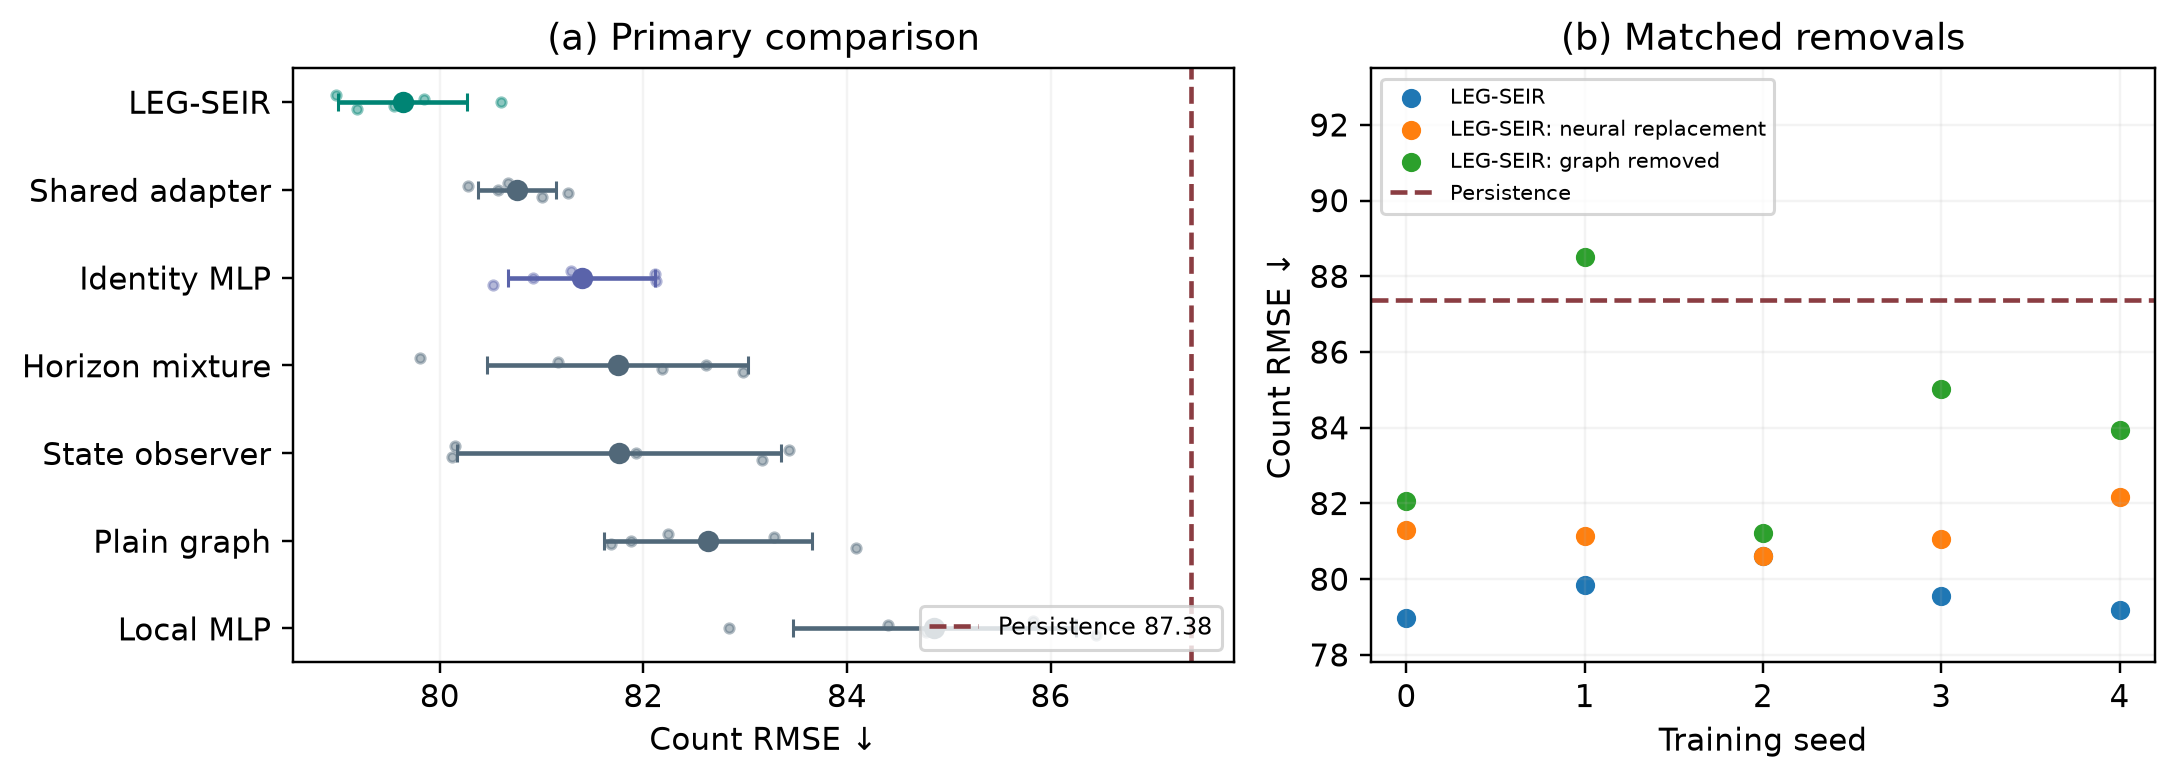

source_coverage.png


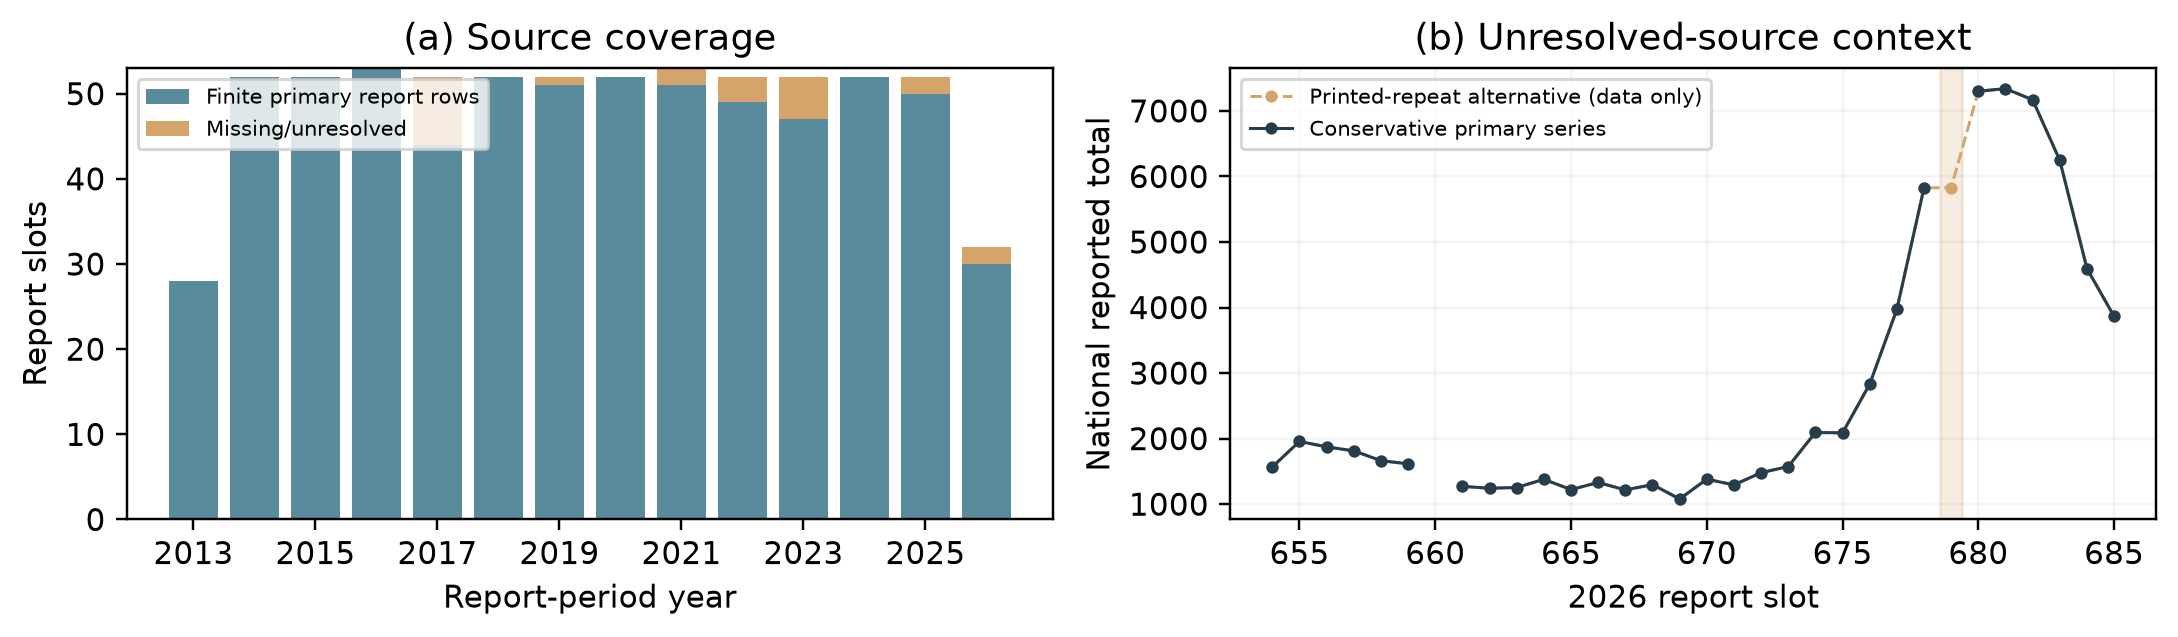

training_curves.png


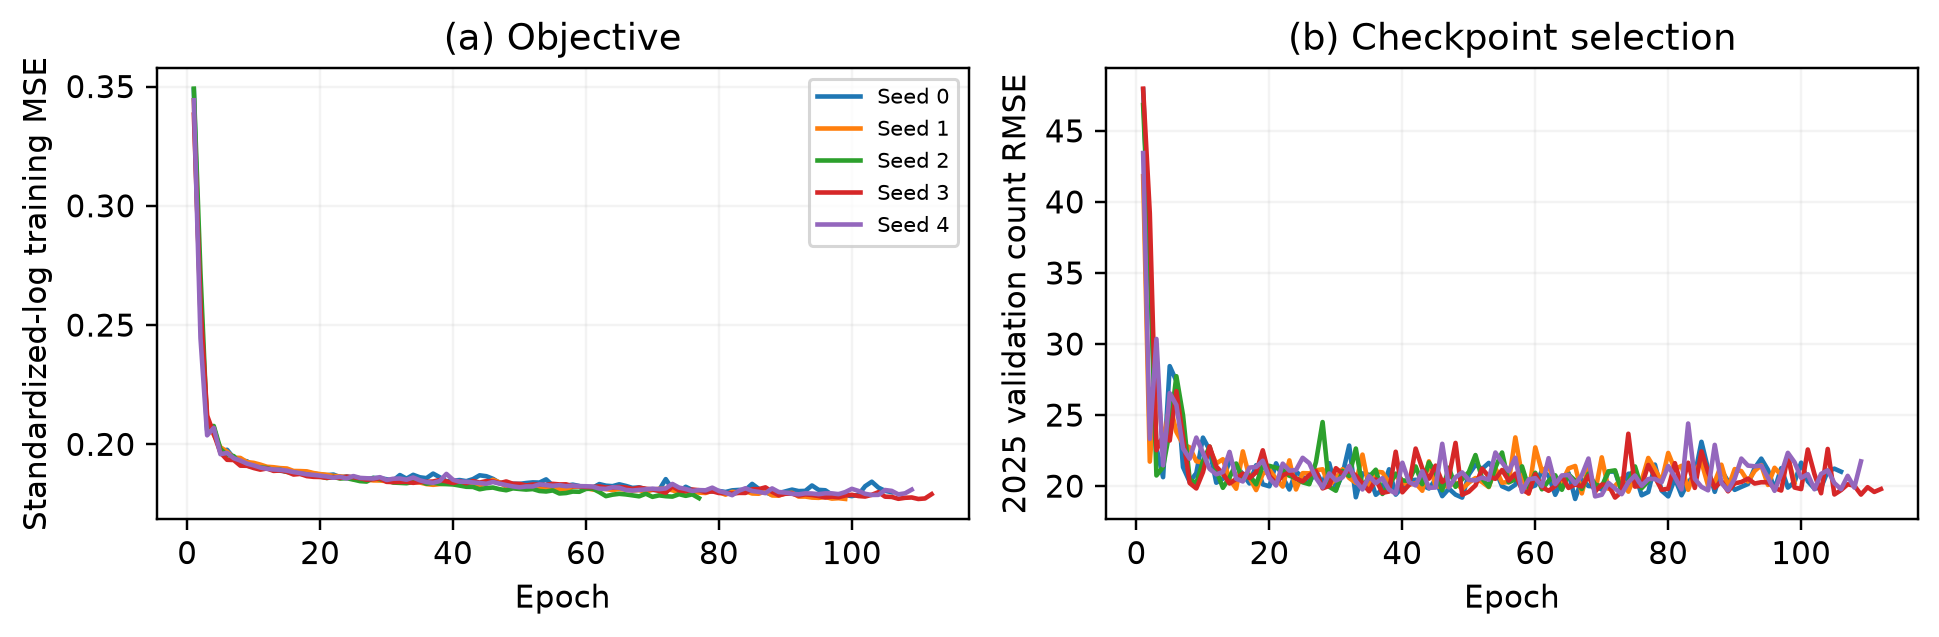

In [2]:
subprocess.run([sys.executable,str(ROOT/'scripts/build_figures.py')],cwd=ROOT,check=True)
for p in sorted((ROOT/'figures/publication').glob('*.png')):
 print(p.name)
 display(Image(filename=str(p),width=1000))
